<a href="https://colab.research.google.com/github/Sirfowahid/Vision-Transformer-Compression-and-Deployment/blob/main/Week_14_Capstone_Build_Compress_and_Deploy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 14 (Capstone): Build, Compress and Deploy a Vision Model 🏁

For thirteen weeks you built the individual pieces. This capstone **chains them into one engineering project**, the way it happens at work:

> **The brief.** Your team has a scene-recognition task. A big pretrained ViT gets the accuracy, but it is far too heavy to ship. Deliver a model that (1) is **accurate**, (2) is **small enough to download**, (3) is **fast on a plain CPU**, and (4) **actually runs outside your training notebook**. Then **prove** you met the requirements, and say honestly where you did not.

```
  Stage A                 Stage B                 Stage C                    Stage D                 Stage E
  LoRA-tune a ViT   ───▶  Distill into a   ───▶   Prune + int8-pack     ───▶  Export & serve    ───▶  Scorecard, budget check,
  (Week 11)               small CNN (Week 13)     (Weeks 13)                 (TorchScript / ONNX)    error analysis, report
```

| Stage | Weeks it builds on | Output |
|---|---|---|
| **A. Teacher** | 9 (ViT), 11 (LoRA) | a LoRA-adapted ViT-B/32; a **1 MB adapter file** instead of a 330 MB checkpoint |
| **B. Student** | 13 (distillation) | a small CNN trained from the teacher's soft labels, against a hard-label control |
| **C. Compression** | 13 (pruning, quantization) | pruned and int8-packed variants, measured for real shipped size |
| **D. Deployment** | new | TorchScript / ONNX export, **output-equivalence checks**, train/serve preprocessing check, a `predict()` function |
| **E. Decision** | new | a budget-based **model selection** (on validation!), paired-bootstrap confidence interval, error analysis |

By the end you will have:
1. Run a full **fine-tune → distill → compress → export** pipeline with a check at every handoff
2. Chosen a model by **requirements written down before the results**, not by eyeballing a plot
3. Quantified the **uncertainty** of the final comparison instead of trusting a single accuracy number
4. Produced the artefacts a reviewer would ask for: model file, model card, and an honest limitations section

> ⚠️ **Educational use only.** A classroom project on a small public dataset, not a production-ready system.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.nn.utils.prune as prune
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from torch.utils.flop_counter import FlopCounterMode
from torchvision import tv_tensors, models
import torchvision.transforms.v2 as transforms_v2

import os
import io
import gzip
import copy
import math
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

print("PyTorch version:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
use_amp = (device.type == "cuda")   # mixed precision (Week 5)
if not use_amp:
    print("⚠️ No GPU detected. Training will be slow. Enable one in Runtime > Change runtime type.")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

PyTorch version: 2.14.1+cu130
Using device: cuda


### 📋 The Requirements (decided *before* we look at any results)

A requirement you write after seeing the numbers is a justification, not a requirement. These thresholds are set now; **model selection later uses validation accuracy only** (the test set is touched once, for the final report).

| Requirement | Threshold | Why |
|---|---|---|
| **Accuracy** | at most **2 points** below the teacher (validation) | the business tolerates a small loss |
| **Speed** | at least **4× faster** than the teacher, batch-1 CPU | interactive use on cheap hardware |
| **Size** | shipped checkpoint of at most **20 MB** (gzip-compressed) | app-store / over-the-air update limit |

Change the numbers to play "what if the budget were stricter?", but change them **before** you re-run Stage E, not after.

In [ ]:
ACC_DROP_BUDGET = 2.0     # points of validation accuracy below the teacher
MIN_SPEEDUP     = 4.0     # x faster than the teacher on CPU, batch 1
MAX_SIZE_MB     = 20.0    # gzip-compressed shipped checkpoint

## 1. Data

Same Intel scene data as Weeks 9, 12 and 13 (6 classes, 128×128 stored, 90/10 train/val split of the training folder, official test folder held out). Students see 128×128; the teacher receives an upscaled 224×224 copy of the **same augmented batch**.

Same Kaggle secret setup as before (`KAGGLE_API_TOKEN` in Colab Secrets).

In [ ]:
from google.colab import userdata

kaggle_token = userdata.get("KAGGLE_API_TOKEN")
os.environ["KAGGLE_API_TOKEN"] = kaggle_token

!pip install -q kagglehub
import kagglehub

dataset_path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Dataset downloaded to:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded to: /kaggle/input/intel-image-classification
intel-image-classification/
  seg_train/
    seg_train/
      mountain/
      street/
      buildings/
      sea/
      forest/
      glacier/
  seg_pred/
    seg_pred/
  seg_test/
    seg_test/
      mountain/
      street/
      buildings/
      sea/
      forest/
      glacier/


In [ ]:
IMG_EXT = (".jpg", ".jpeg", ".png")
train_list, test_list, seen = [], [], set()

for root, dirs, files in os.walk(dataset_path):
    parts = root.replace(dataset_path, "").lower().split(os.sep)
    if "seg_pred" in parts:
        continue                                   # unlabeled images: skip
    split = "train" if "seg_train" in parts else ("test" if "seg_test" in parts else None)
    cls = os.path.basename(root)
    if split is None or cls.lower() in ("seg_train", "seg_test"):
        continue
    for f in files:
        if f.lower().endswith(IMG_EXT) and (split, cls, f) not in seen:
            seen.add((split, cls, f))
            (train_list if split == "train" else test_list).append((os.path.join(root, f), cls))

class_names = sorted({c for _, c in train_list})
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print(f"Labeled training images: {len(train_list):,} | labeled test images: {len(test_list):,}")

IMG_SIZE = 128
def load_split(items, desc):
    imgs = np.empty((len(items), 3, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    labels = np.empty(len(items), dtype=np.int64)
    for i, (path, cls) in enumerate(tqdm(items, desc=desc)):
        img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        imgs[i] = np.asarray(img).transpose(2, 0, 1)
        labels[i] = class_to_idx[cls]
    return torch.from_numpy(imgs), torch.from_numpy(labels)

pool_images, pool_labels = load_split(train_list, "Loading train")
test_images, test_labels = load_split(test_list, "Loading test")

perm = torch.randperm(len(pool_images), generator=torch.Generator().manual_seed(SEED))
n_val = int(0.10 * len(perm))
val_idx, train_idx = perm[:n_val].numpy(), perm[n_val:].numpy()
val_images, val_labels = pool_images[val_idx], pool_labels[val_idx]
train_images, train_labels = pool_images[train_idx], pool_labels[train_idx]
del pool_images, pool_labels
print(f"\nTrain: {len(train_images):,} | Val: {len(val_images):,} | Test: {len(test_images):,}")

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Labeled training images: 14,034 | labeled test images: 3,000


Loading train:   0%|          | 0/14034 [00:00<?, ?it/s]

Loading test:   0%|          | 0/3000 [00:00<?, ?it/s]


Train: 12,631 | Val: 1,403 | Test: 3,000


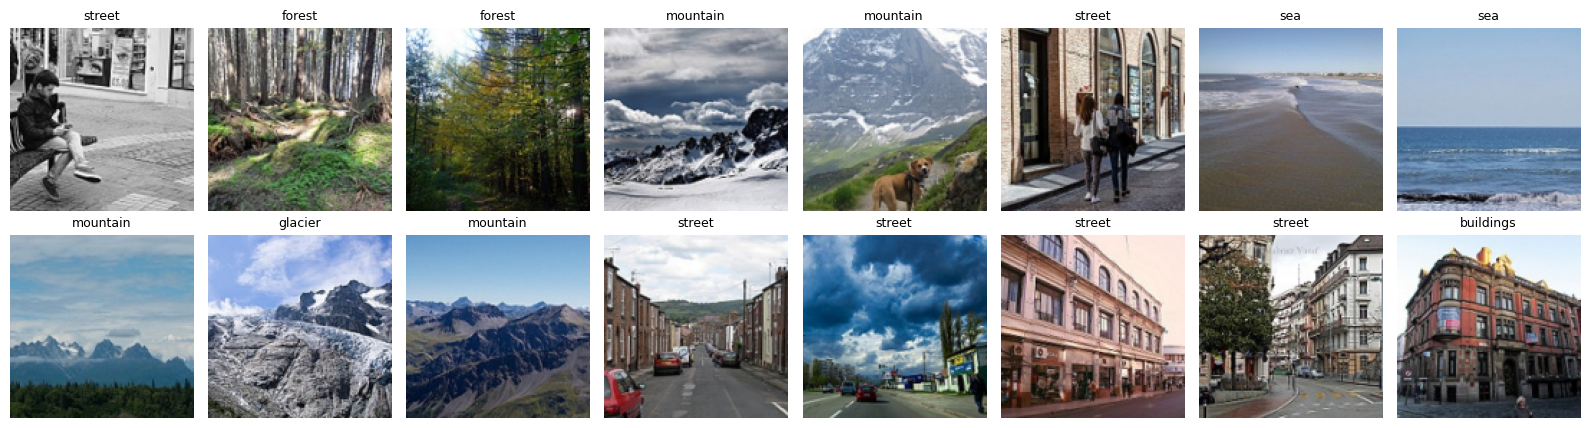

In [ ]:
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_t = transforms_v2.Compose([
    transforms_v2.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), antialias=True),
    transforms_v2.RandomHorizontalFlip(),
    transforms_v2.ToDtype(torch.float32, scale=True),
    transforms_v2.Normalize(mean=IMNET_MEAN, std=IMNET_STD),
])
eval_t = transforms_v2.Compose([
    transforms_v2.ToDtype(torch.float32, scale=True),
    transforms_v2.Normalize(mean=IMNET_MEAN, std=IMNET_STD),
])

class ImageDataset(Dataset):
    def __init__(self, images, labels, indices, transform):
        self.images, self.labels = images, labels
        self.indices = np.asarray(indices)
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        g = self.indices[i]
        return self.transform(tv_tensors.Image(self.images[g])).as_subclass(torch.Tensor), int(self.labels[g])

BATCH_SIZE = 64
train_loader = DataLoader(ImageDataset(train_images, train_labels, np.arange(len(train_images)), train_t), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
val_loader   = DataLoader(ImageDataset(val_images,  val_labels,  np.arange(len(val_images)),  eval_t), batch_size=128, shuffle=False, num_workers=2)
test_loader  = DataLoader(ImageDataset(test_images, test_labels, np.arange(len(test_images)), eval_t), batch_size=128, shuffle=False, num_workers=2)

def upscale(x):                                 # 128 -> 224 for the ViT teacher, on the GPU
    return F.interpolate(x, size=224, mode="bilinear", align_corners=False)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
rng = np.random.default_rng(SEED)
for ax, i in zip(axes.ravel(), rng.choice(len(train_images), 16, replace=False)):
    ax.imshow(train_images[i].permute(1, 2, 0).numpy()); ax.set_title(class_names[train_labels[i]], fontsize=9); ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Shared Machinery

The evaluation helpers (accuracy, NLL, ECE, teacher agreement) and the generic training loop `fit` from Week 13: AdamW, warmup + cosine, mixed precision, **best epoch chosen on validation**.

In [ ]:
@torch.no_grad()
def get_logits(model, loader, prep=None):
    model.eval()
    out = []
    for images, _ in loader:
        images = images.to(device)
        if prep is not None:
            images = prep(images)
        with autocast(device_type=device.type, enabled=use_amp):
            out.append(model(images).float().cpu())
    return torch.cat(out)


def ece_score(probs, labels, n_bins=10):
    conf, pred = probs.max(1)
    acc = (pred == labels).float()
    ece = 0.0
    edges = torch.linspace(0, 1, n_bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.float().mean().item() * abs(acc[m].mean().item() - conf[m].mean().item())
    return ece


def metrics_from_logits(logits, labels, teacher_logits=None):
    probs = logits.softmax(1)
    out = {"acc": (logits.argmax(1) == labels).float().mean().item(),
           "nll": F.cross_entropy(logits, labels).item(),
           "ece": ece_score(probs, labels)}
    if teacher_logits is not None:
        out["agree"] = (logits.argmax(1) == teacher_logits.argmax(1)).float().mean().item()
    return out


def fit(model, step_fn, epochs, lr, weight_decay, params=None, prep=None, warmup_epochs=1, verbose=True, tag=""):
    # step_fn(images, labels) -> scalar loss (computed inside autocast). Restores the best epoch (by validation accuracy).
    params = params if params is not None else [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    total, warm = epochs * len(train_loader), warmup_epochs * len(train_loader)
    sched = optim.lr_scheduler.LambdaLR(optimizer, lambda s: (s + 1) / warm if s < warm
                                        else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = GradScaler(enabled=use_amp)
    hist = {"train_loss": [], "val_acc": []}
    best_acc, best_state, t0 = -1.0, None, time.time()
    for epoch in range(epochs):
        model.train()
        running, n = 0.0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            with autocast(device_type=device.type, enabled=use_amp):
                loss = step_fn(images, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(optimizer); scaler.update(); sched.step()
            running += loss.item() * labels.size(0); n += labels.size(0)
        val_acc = (get_logits(model, val_loader, prep).argmax(1) == val_labels).float().mean().item()
        hist["train_loss"].append(running / n); hist["val_acc"].append(val_acc)
        star = ""
        if val_acc > best_acc:
            best_acc, best_state = val_acc, copy.deepcopy(model.state_dict()); star = "  ⭐"
        if verbose:
            print(f"  {tag}Epoch [{epoch+1:2d}/{epochs}]  Train Loss: {running/n:.4f}  Val Acc: {val_acc:.4f}{star}")
    model.load_state_dict(best_state)
    hist["time"] = time.time() - t0
    return model, hist

## 3. Stage A: The Teacher, LoRA-Tuned

Week 11's from-scratch LoRA, reused. Recall the idea: freeze the pretrained weights `W` and learn a low-rank update, `y = xWᵀ + (α/r)·x AᵀBᵀ`, with `B = 0` at the start so the model begins **exactly** where the pretrained model is. torchvision's ViT hides attention in a fused `nn.MultiheadAttention`, so we first swap in a split-projection attention that is **proven identical**, then wrap the query and value projections.

In [ ]:
def load_vit():
    vit = models.vit_b_32(weights=models.ViT_B_32_Weights.IMAGENET1K_V1)
    vit.heads = nn.Sequential(nn.Linear(vit.hidden_dim, NUM_CLASSES))
    nn.init.zeros_(vit.heads[0].weight); nn.init.zeros_(vit.heads[0].bias)
    return vit


class ViTAttention(nn.Module):
    # drop-in replacement for nn.MultiheadAttention in a torchvision ViT block, with SEPARATE q/k/v/out projections
    def __init__(self, dim, num_heads):
        super().__init__()
        self.h, self.dk = num_heads, dim // num_heads
        self.q_proj, self.k_proj, self.v_proj, self.out_proj = (nn.Linear(dim, dim) for _ in range(4))

    @classmethod
    def from_mha(cls, mha):
        dim = mha.embed_dim
        m = cls(dim, mha.num_heads)
        W, b = mha.in_proj_weight.detach(), mha.in_proj_bias.detach()
        for i, lin in enumerate([m.q_proj, m.k_proj, m.v_proj]):
            lin.weight.data.copy_(W[i * dim:(i + 1) * dim]); lin.bias.data.copy_(b[i * dim:(i + 1) * dim])
        m.out_proj.load_state_dict(mha.out_proj.state_dict())
        return m

    def forward(self, query, key=None, value=None, need_weights=False):
        x = query
        B, N, D = x.shape
        q, k, v = (proj(x).reshape(B, N, self.h, self.dk).transpose(1, 2) for proj in (self.q_proj, self.k_proj, self.v_proj))
        out = F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, D)
        return self.out_proj(out), None


class LoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16):
        super().__init__()
        self.base, self.r, self.scaling, self.merged = base, r, alpha / r, False
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))            # B = 0  =>  starts identical to the base model
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))

    def forward(self, x):
        out = self.base(x)
        return out if self.merged else out + (x @ self.lora_A.T @ self.lora_B.T) * self.scaling

    @torch.no_grad()
    def merge(self):
        if not self.merged:
            self.base.weight += (self.lora_B @ self.lora_A) * self.scaling
            self.merged = True


def apply_lora(vit, r=8, alpha=16):
    for blk in vit.encoder.layers:
        attn = ViTAttention.from_mha(blk.self_attention)
        blk.self_attention = attn
        attn.q_proj, attn.v_proj = LoRALinear(attn.q_proj, r, alpha), LoRALinear(attn.v_proj, r, alpha)
    for name, p in vit.named_parameters():
        p.requires_grad = ("lora_" in name) or name.startswith("heads")
    return vit


def lora_modules(model):
    return [m for m in model.modules() if isinstance(m, LoRALinear)]


def vit_embed_logits(vit, x):
    x = vit._process_input(x)
    x = torch.cat([vit.class_token.expand(x.shape[0], -1, -1), x], dim=1)
    emb = vit.encoder(x)[:, 0]
    return emb, vit.heads(emb)


# CHECKS: (1) split attention == the original, (2) LoRA model == base model at initialisation, (3) parameter count matches the formula
set_seed()
base = load_vit().eval()
nn.init.normal_(base.heads[0].weight, std=0.02)
x = torch.randn(2, 3, 224, 224)
with torch.no_grad():
    xs = torch.randn(2, 50, 768)
    ref, _ = base.encoder.layers[0].self_attention(xs, xs, xs, need_weights=False)
    ours, _ = ViTAttention.from_mha(base.encoder.layers[0].self_attention).eval()(xs, xs, xs)
print("1) split attention == nn.MultiheadAttention:", torch.allclose(ref, ours, atol=1e-5)); assert torch.allclose(ref, ours, atol=1e-5)
lm = apply_lora(copy.deepcopy(base), r=8, alpha=16).eval()
with torch.no_grad():
    same = torch.allclose(base(x), lm(x), atol=1e-4)
print("2) LoRA model == base model at initialisation:", same); assert same
n_lora = sum(p.numel() for n, p in lm.named_parameters() if "lora_" in n)
print(f"3) LoRA parameters {n_lora:,} == formula 12 x 2 x 8 x (768+768) = {12*2*8*1536:,}:", n_lora == 12 * 2 * 8 * 1536); assert n_lora == 12 * 2 * 8 * 1536
del base, lm

Downloading: "https://download.pytorch.org/models/vit_b_32-d86f8d99.pth" to /root/.cache/torch/hub/checkpoints/vit_b_32-d86f8d99.pth


100%|██████████| 337M/337M [00:01<00:00, 179MB/s]


1) split attention == nn.MultiheadAttention: True
2) LoRA model == base model at initialisation: True
3) LoRA parameters 294,912 == formula 12 x 2 x 8 x (768+768) = 294,912: True


In [ ]:
EPOCHS_TEACHER = 4
set_seed()
teacher = apply_lora(load_vit(), r=8, alpha=16).to(device)
n_train = sum(p.numel() for p in teacher.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in teacher.parameters())
print(f"Trainable: {n_train:,} of {n_all:,} parameters ({100*n_train/n_all:.2f}%)")

teacher_step = lambda x, y: F.cross_entropy(teacher(upscale(x)).float(), y)
teacher, teacher_hist = fit(teacher, teacher_step, EPOCHS_TEACHER, lr=1e-3, weight_decay=0.01, prep=upscale, tag="[LoRA teacher] ")

# The deliverable of Stage A on its own: just the adapter + head, not the 330 MB model
adapter = {k: v.cpu() for k, v in teacher.state_dict().items() if "lora_" in k or k.startswith("heads")}
buf = io.BytesIO(); torch.save(adapter, buf)
print(f"\nAdapter-only checkpoint: {len(buf.getvalue())/2**20:.2f} MB   vs   full model: {sum(v.numel()*v.element_size() for v in teacher.state_dict().values())/2**20:.0f} MB")

Trainable: 299,526 of 87,754,758 parameters (0.34%)
  [LoRA teacher] Epoch [ 1/4]  Train Loss: 0.5918  Val Acc: 0.9337  ⭐
  [LoRA teacher] Epoch [ 2/4]  Train Loss: 0.1837  Val Acc: 0.9437  ⭐
  [LoRA teacher] Epoch [ 3/4]  Train Loss: 0.1476  Val Acc: 0.9444  ⭐
  [LoRA teacher] Epoch [ 4/4]  Train Loss: 0.1164  Val Acc: 0.9423

Adapter-only checkpoint: 1.16 MB   vs   full model: 335 MB


### Two handoff checks before we trust this teacher
Every stage hands something to the next one, and handoffs are where pipelines silently break.
1. **Adapter portability:** load *only* the adapter onto a fresh pretrained ViT. It must reproduce the teacher's predictions exactly. (This is what lets you ship 1 MB per task.)
2. **Merging is lossless:** fold `BA` into `W` and unwrap. The result is a plain ViT with **no LoRA overhead**, and its outputs must not change. The distillation stage will use this merged teacher.

In [ ]:
teacher.eval()
xb, _ = next(iter(val_loader)); xb = upscale(xb.to(device))
with torch.no_grad():
    ref = teacher(xb).float()

# 1) adapter portability
fresh = apply_lora(load_vit(), r=8, alpha=16).to(device)
missing = fresh.load_state_dict(adapter, strict=False)
assert not missing.unexpected_keys
with torch.no_grad():
    port = fresh.eval()(xb).float()
print("1) fresh pretrained ViT + adapter file == trained teacher: max |diff| =", f"{(port - ref).abs().max().item():.2e}")
assert (port - ref).abs().max().item() < 1e-2
del fresh

# 2) merge and unwrap
for m in lora_modules(teacher):
    m.merge()
for blk in teacher.encoder.layers:
    blk.self_attention.q_proj, blk.self_attention.v_proj = blk.self_attention.q_proj.base, blk.self_attention.v_proj.base
for p in teacher.parameters():
    p.requires_grad = False
teacher.eval()
with torch.no_grad():
    merged = teacher(xb).float()
print("2) merged plain ViT vs LoRA ViT: max |diff| =", f"{(merged - ref).abs().max().item():.2e}")
assert (merged - ref).abs().max().item() < 1e-2

teacher_val_logits  = get_logits(teacher, val_loader,  prep=upscale)
teacher_test_logits = get_logits(teacher, test_loader, prep=upscale)
teacher_metrics = metrics_from_logits(teacher_test_logits, test_labels)
print(f"\nTeacher VAL acc {(teacher_val_logits.argmax(1) == val_labels).float().mean()*100:.2f}% | "
      f"TEST: accuracy {teacher_metrics['acc']*100:.2f}% | NLL {teacher_metrics['nll']:.3f} | ECE {teacher_metrics['ece']:.3f}")

1) fresh pretrained ViT + adapter file == trained teacher: max |diff| = 0.00e+00
2) merged plain ViT vs LoRA ViT: max |diff| = 3.70e-06

Teacher VAL acc 94.44% | TEST: accuracy 94.43% | NLL 0.153 | ECE 0.008


## 4. Stage B: Distil the Teacher into Small Students

Settings fixed **in advance** from Week 13 (`T = 4`, `α = 0.5`, online teacher on the same augmented batch). Three runs:

| Run | Purpose |
|---|---|
| **ResNet-18, hard labels** | the *control*: what you get without a teacher |
| **ResNet-18, distilled** | the main candidate (~11M parameters) |
| **TinyCNN, distilled** | the aggressive candidate (~0.3M parameters) |

> ⏱️ Each epoch also runs the teacher forward. With `EPOCHS_STUDENT = 12`, expect roughly 15-20 minutes on a Colab T4.

In [ ]:
def distill_loss(s_logits, t_logits, labels, T=4.0, alpha=0.5):
    soft = F.kl_div(F.log_softmax(s_logits / T, dim=1), F.softmax(t_logits / T, dim=1), reduction="batchmean") * (T * T)
    hard = F.cross_entropy(s_logits, labels)
    return alpha * soft + (1 - alpha) * hard


def cosine_embed_loss(pred, target):
    return (1 - F.cosine_similarity(pred, target.detach(), dim=1)).mean()


# CHECKS
s, t, y = torch.randn(16, 6), torch.randn(16, 6), torch.randint(0, 6, (16,))
print("1) alpha = 0 equals plain cross-entropy:", torch.allclose(distill_loss(s, t, y, alpha=0.0), F.cross_entropy(s, y)))
print("2) soft term is ~0 when student == teacher:", round(distill_loss(t, t, y, T=4, alpha=1.0).item(), 6))
assert torch.allclose(distill_loss(s, t, y, alpha=0.0), F.cross_entropy(s, y)) and distill_loss(t, t, y, T=4, alpha=1.0).item() < 1e-5

print("3) gradient norm of the soft term w.r.t. the student logits (random logits):")
print(f"   {'T':>3}  {'with T^2':>10}  {'without T^2':>12}")
for T in (1, 2, 4, 8):
    s_ = s.clone().requires_grad_(True)
    (F.kl_div(F.log_softmax(s_ / T, 1), F.softmax(t / T, 1), reduction="batchmean") * T * T).backward(); g_with = s_.grad.norm().item()
    s_ = s.clone().requires_grad_(True)
    F.kl_div(F.log_softmax(s_ / T, 1), F.softmax(t / T, 1), reduction="batchmean").backward(); g_without = s_.grad.norm().item()
    print(f"   {T:>3}  {g_with:>10.4f}  {g_without:>12.4f}")

1) alpha = 0 equals plain cross-entropy: True
2) soft term is ~0 when student == teacher: 0.0
3) gradient norm of the soft term w.r.t. the student logits (random logits):
     T    with T^2   without T^2
     1      0.1256        0.1256
     2      0.1290        0.0322
     4      0.1282        0.0080
     8      0.1276        0.0020


In [ ]:
class ResNet18Student(nn.Module):
    def __init__(self, n_classes=NUM_CLASSES):
        super().__init__()
        r = models.resnet18(weights=None)
        r.fc = nn.Identity()
        self.backbone, self.feat_dim = r, 512
        self.head = nn.Linear(512, n_classes)
    def forward(self, x, return_feat=False):
        f = self.backbone(x)
        out = self.head(f)
        return (out, f) if return_feat else out


class TinyCNN(nn.Module):
    def __init__(self, n_classes=NUM_CLASSES, widths=(16, 32, 64, 128)):
        super().__init__()
        layers, c_in = [], 3
        for w in widths:
            layers += [nn.Conv2d(c_in, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
                       nn.Conv2d(w, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = w
        self.features, self.pool, self.feat_dim = nn.Sequential(*layers), nn.AdaptiveAvgPool2d(1), widths[-1]
        self.head = nn.Linear(widths[-1], n_classes)
    def forward(self, x, return_feat=False):
        f = self.pool(self.features(x)).flatten(1)
        out = self.head(f)
        return (out, f) if return_feat else out


STUDENT_ARCHS = {"ResNet-18": ResNet18Student, "TinyCNN": TinyCNN}
for name, cls in STUDENT_ARCHS.items():
    m = cls()
    with torch.no_grad():
        out, feat = m.eval()(torch.randn(2, 3, IMG_SIZE, IMG_SIZE), return_feat=True)
    print(f"{name:<10} {sum(p.numel() for p in m.parameters())/1e6:6.2f}M parameters | logits {tuple(out.shape)} | feature {tuple(feat.shape)}")
print(f"{'Teacher':<10} {sum(p.numel() for p in teacher.parameters())/1e6:6.2f}M parameters")

ResNet-18   11.18M parameters | logits (2, 6) | feature (2, 512)
TinyCNN      0.29M parameters | logits (2, 6) | feature (2, 128)
Teacher     87.46M parameters


In [ ]:
EPOCHS_STUDENT = 12
student_runs = {}

def make_step(student, mode, T=4.0, alpha=0.5):
    def step(x, y):
        if mode == "hard":
            return F.cross_entropy(student(x).float(), y)
        with torch.no_grad():
            _, t_logits = vit_embed_logits(teacher, upscale(x))              # the teacher sees the SAME augmented images
        return distill_loss(student(x).float(), t_logits.float(), y, T, alpha)
    return step

def run_student(arch, mode, epochs=EPOCHS_STUDENT):
    set_seed()
    student = STUDENT_ARCHS[arch]().to(device)
    student, hist = fit(student, make_step(student, mode), epochs, lr=2e-3, weight_decay=0.05, verbose=False)
    v, t = get_logits(student, val_loader), get_logits(student, test_loader)
    student_runs[(arch, mode)] = dict(model=student, hist=hist, val=metrics_from_logits(v, val_labels, teacher_val_logits),
                                      test=metrics_from_logits(t, test_labels, teacher_test_logits))
    r = student_runs[(arch, mode)]
    print(f"  {arch:<10} {mode:<5} | VAL acc {r['val']['acc']*100:5.2f}% | TEST acc {r['test']['acc']*100:5.2f}% | "
          f"ECE {r['test']['ece']:.3f} | agrees with teacher {r['test']['agree']*100:5.1f}% | {hist['time']:.0f}s")

for arch, mode in [("ResNet-18", "hard"), ("ResNet-18", "kd"), ("TinyCNN", "kd")]:
    run_student(arch, mode)

  ResNet-18  hard  | VAL acc 90.02% | TEST acc 89.20% | ECE 0.007 | agrees with teacher  90.9% | 226s
  ResNet-18  kd    | VAL acc 90.73% | TEST acc 90.17% | ECE 0.034 | agrees with teacher  92.1% | 266s
  TinyCNN    kd    | VAL acc 90.52% | TEST acc 89.93% | ECE 0.019 | agrees with teacher  91.4% | 249s


## 5. Stage C: Compress the Student

Starting from the distilled ResNet-18 we apply, in order:

1. **Global magnitude pruning** at several sparsities, each followed by distillation fine-tuning (the zeros stay frozen by the mask).
2. **int8 weight packing**, a *real* storage format this time (not simulated): every conv/linear weight becomes an `int8` tensor plus one fp32 scale **per output channel**; everything else (BatchNorm, biases) stays fp32. At load time we dequantize.

### What each step buys, honestly
- **Pruning** shrinks the *gzip-compressed* file (zeros compress) but **not** dense latency or FLOPs.
- **int8 packing** shrinks the *download* by ~4× (and compresses further when combined with pruning), but with weight-only packing **the compute is still fp32 after dequantization**. It is a *storage and bandwidth* win, not a speed win. Real int8 *speedups* need int8 kernels and activation quantization (static/QAT, or a runtime like ONNX Runtime / TensorRT), which is beyond this capstone.

Both are **round-trip checked**: pack → unpack must reproduce the simulated-quantized weights exactly, and pruned zeros must survive packing.

In [ ]:
def prunable(model):
    return [(m, "weight") for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]

def global_sparsity(model):
    z = t = 0
    for m, _ in prunable(model):
        z += (m.weight == 0).sum().item(); t += m.weight.numel()
    return z / t

def make_permanent(model):
    for m, _ in prunable(model):
        if prune.is_pruned(m):
            prune.remove(m, "weight")
    return model

def val_acc_of(model, prep=None):
    return (get_logits(model, val_loader, prep).argmax(1) == val_labels).float().mean().item()

def test_acc_of(model, prep=None):
    return (get_logits(model, test_loader, prep).argmax(1) == test_labels).float().mean().item()

def gz_bytes(obj):
    buf = io.BytesIO(); torch.save(obj, buf)
    return len(gzip.compress(buf.getvalue(), compresslevel=6))

def raw_bytes(obj):
    buf = io.BytesIO(); torch.save(obj, buf)
    return len(buf.getvalue())

# ---------- real int8 packing: int8 tensor + per-output-channel fp32 scale ----------
def pack_int8(model):
    packed = {}
    for k, v in model.state_dict().items():
        if v.ndim in (2, 4) and v.is_floating_point():
            scale = (v.abs().amax(dim=tuple(range(1, v.ndim)), keepdim=True) / 127).clamp(min=1e-12)
            packed[k] = {"q": torch.round(v / scale).clamp(-127, 127).to(torch.int8).cpu(), "scale": scale.float().cpu()}
        else:
            packed[k] = v.cpu()
    return packed

def unpack_int8(packed, model):
    sd = {k: (v["q"].float() * v["scale"] if isinstance(v, dict) else v) for k, v in packed.items()}
    model.load_state_dict(sd)
    return model

# CHECK: round trip equals the simulated per-channel 8-bit quantization, and zeros survive
t = copy.deepcopy(student_runs[("ResNet-18", "kd")]["model"]).cpu()
prune.global_unstructured(prunable(t), pruning_method=prune.L1Unstructured, amount=0.8); make_permanent(t)
rt = unpack_int8(pack_int8(t), copy.deepcopy(t))
w_err = max((a - b).abs().max().item() for (a, b) in zip(rt.parameters(), t.parameters()))
print(f"pruned 80% -> sparsity {global_sparsity(t)*100:.1f}% | after int8 round trip sparsity {global_sparsity(rt)*100:.1f}% | max weight error {w_err:.2e}")
assert abs(global_sparsity(t) - 0.8) < 0.01 and abs(global_sparsity(rt) - global_sparsity(t)) < 1e-6
print(f"checkpoint: fp32 {raw_bytes(t.state_dict())/2**20:.1f} MB | int8 packed {raw_bytes(pack_int8(t))/2**20:.1f} MB | "
      f"int8 packed + gzip {gz_bytes(pack_int8(t))/2**20:.1f} MB")
del t, rt

pruned 80% -> sparsity 80.0% | after int8 round trip sparsity 80.0% | max weight error 1.88e-03
checkpoint: fp32 42.7 MB | int8 packed 10.8 MB | int8 packed + gzip 3.6 MB


In [ ]:
PRUNE_LEVELS = (0.5, 0.8, 0.9)
EPOCHS_PRUNE_FT = 3
base_student = student_runs[("ResNet-18", "kd")]["model"]
pruned = {}
for amount in PRUNE_LEVELS:
    set_seed()
    m = copy.deepcopy(base_student)
    prune.global_unstructured(prunable(m), pruning_method=prune.L1Unstructured, amount=amount)
    before = val_acc_of(m)
    m, _ = fit(m, make_step(m, "kd"), EPOCHS_PRUNE_FT, lr=5e-4, weight_decay=0.0, warmup_epochs=0, verbose=False)
    make_permanent(m)
    pruned[amount] = m
    print(f"prune {amount*100:3.0f}% | sparsity {global_sparsity(m)*100:5.1f}% | val acc: right after pruning {before*100:5.2f}% -> after KD fine-tuning {val_acc_of(m)*100:5.2f}%")

prune  50% | sparsity  50.0% | val acc: right after pruning 89.95% -> after KD fine-tuning 91.23%
prune  80% | sparsity  80.0% | val acc: right after pruning 63.15% -> after KD fine-tuning 90.88%
prune  90% | sparsity  90.0% | val acc: right after pruning 20.53% -> after KD fine-tuning 90.66%


## 6. The Candidate Table

We now have a family of models. For each we measure everything a deployment review asks about. Two definitions matter:

- **Shipped size** = gzip-compressed size of what you would actually put in the download (the **int8-packed** file for the int8 variants, the fp32 state dict otherwise).
- **Latency** = median batch-1 forward pass on CPU after warm-up (fp32 eager PyTorch). The int8-packed variants are dequantized at load time, so they run at the **same speed** as their fp32 source: a storage win only.

FLOPs, parameters, size and latency are **different quantities**, so we report all of them.

In [ ]:
CPU = torch.device("cpu")

def count_flops(model, shape):
    m = copy.deepcopy(model).to(CPU).eval()
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        m(torch.randn(*shape))
    return fc.get_total_flops() / 1e9

def time_fn(fn, x, n_warmup=5, n_iter=20):
    with torch.no_grad():
        for _ in range(n_warmup): fn(x)
        ts = []
        for _ in range(n_iter):
            t0 = time.perf_counter(); fn(x); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

def latency_ms(model, shape):
    m = copy.deepcopy(model).to(CPU).eval()
    return time_fn(m, torch.randn(*shape))

def nonzero_params(model):
    return sum((p != 0).sum().item() for p in model.parameters())

def int8_roundtrip(model):
    m = copy.deepcopy(model).cpu()
    return unpack_int8(pack_int8(m), m).to(device).eval(), pack_int8(model)

cands = []
def add(name, model, shape, prep, shipped_obj, is_teacher=False):
    model = model.eval()
    cands.append(dict(name=name, model=model, shape=shape, prep=prep, is_teacher=is_teacher,
                      val=val_acc_of(model, prep) * 100, test=test_acc_of(model, prep) * 100,
                      params=sum(p.numel() for p in model.parameters()) / 1e6, nonzero=nonzero_params(model) / 1e6,
                      gz=gz_bytes(shipped_obj) / 2**20, gflops=count_flops(model, shape), cpu=latency_ms(model, shape)))
    print(f"  measured: {name}")

S128, S224 = (1, 3, 128, 128), (1, 3, 224, 224)
add("Teacher: LoRA ViT-B/32 (merged)", teacher, S224, upscale, teacher.state_dict(), is_teacher=True)
add("ResNet-18, hard labels", student_runs[("ResNet-18", "hard")]["model"], S128, None, student_runs[("ResNet-18", "hard")]["model"].state_dict())
add("ResNet-18, distilled", base_student, S128, None, base_student.state_dict())
for amount in PRUNE_LEVELS:
    add(f"ResNet-18, distilled + {amount*100:.0f}% pruned", pruned[amount], S128, None, pruned[amount].state_dict())
    m8, packed = int8_roundtrip(pruned[amount])
    add(f"ResNet-18, distilled + {amount*100:.0f}% pruned + int8", m8, S128, None, packed)
tiny = student_runs[("TinyCNN", "kd")]["model"]
add("TinyCNN, distilled", tiny, S128, None, tiny.state_dict())
tiny8, tpacked = int8_roundtrip(tiny)
add("TinyCNN, distilled + int8", tiny8, S128, None, tpacked)

T = next(c for c in cands if c["is_teacher"])
print(f"\n{'candidate':<44}{'val %':>7}{'test %':>8}{'params M':>10}{'nonzero M':>10}{'ship MB':>9}{'GFLOPs':>8}{'CPU ms':>8}{'speedup':>8}")
print("-" * 112)
for c in cands:
    print(f"{c['name']:<44}{c['val']:>7.2f}{c['test']:>8.2f}{c['params']:>10.2f}{c['nonzero']:>10.2f}{c['gz']:>9.2f}{c['gflops']:>8.2f}{c['cpu']:>8.1f}{T['cpu']/c['cpu']:>7.1f}x")

  measured: Teacher: LoRA ViT-B/32 (merged)
  measured: ResNet-18, hard labels
  measured: ResNet-18, distilled
  measured: ResNet-18, distilled + 50% pruned
  measured: ResNet-18, distilled + 50% pruned + int8
  measured: ResNet-18, distilled + 80% pruned
  measured: ResNet-18, distilled + 80% pruned + int8
  measured: ResNet-18, distilled + 90% pruned
  measured: ResNet-18, distilled + 90% pruned + int8
  measured: TinyCNN, distilled
  measured: TinyCNN, distilled + int8

candidate                                     val %  test %  params M nonzero M  ship MB  GFLOPs  CPU ms speedup
----------------------------------------------------------------------------------------------------------------
Teacher: LoRA ViT-B/32 (merged)               94.44   94.43     87.46     87.46   310.52    8.72   171.7    1.0x
ResNet-18, hard labels                        90.02   89.20     11.18     11.18    39.64    1.18    24.6    7.0x
ResNet-18, distilled                          90.73   90.17     11.18

## 7. Model Selection Against the Requirements

Now the rule written at the top is applied, **on validation accuracy** (the test column is for the final report only; choosing by test accuracy would quietly overfit the test set, which is exactly what a held-out set is meant to prevent).

**Rule:** among candidates that meet all three requirements, ship the one with the **smallest shipped size** (ties → higher validation accuracy). If none passes, say so, and fall back to the most accurate student, with the shortfall stated plainly.

In [ ]:
for c in cands:
    c["ok_acc"]   = (T["val"] - c["val"]) <= ACC_DROP_BUDGET
    c["ok_speed"] = (T["cpu"] / c["cpu"]) >= MIN_SPEEDUP
    c["ok_size"]  = c["gz"] <= MAX_SIZE_MB
    c["passes"]   = (not c["is_teacher"]) and c["ok_acc"] and c["ok_speed"] and c["ok_size"]

mark = lambda ok: "✅" if ok else "❌"
print(f"Requirements: accuracy within {ACC_DROP_BUDGET} pts of teacher (val {T['val']:.2f}%) | >= {MIN_SPEEDUP}x faster (teacher {T['cpu']:.1f} ms) | <= {MAX_SIZE_MB} MB shipped\n")
print(f"{'candidate':<44}{'accuracy':>10}{'speed':>8}{'size':>7}   verdict")
for c in cands:
    print(f"{c['name']:<44}{mark(c['ok_acc']):>9}{mark(c['ok_speed']):>8}{mark(c['ok_size']):>7}   {'PASSES' if c['passes'] else ('(reference)' if c['is_teacher'] else 'fails')}")

passing = [c for c in cands if c["passes"]]
if passing:
    chosen = min(passing, key=lambda c: (c["gz"], -c["val"]))
    print(f"\n➡️  Selected: {chosen['name']}")
else:
    students = [c for c in cands if not c["is_teacher"]]
    chosen = max(students, key=lambda c: c["val"])
    print(f"\n⚠️  NO candidate meets all three requirements. Falling back to the most accurate student: {chosen['name']}")
    print("   Report this honestly: which requirement failed, by how much, and what you would change (longer distillation, a bigger student, a looser budget).")

Requirements: accuracy within 2.0 pts of teacher (val 94.44%) | >= 4.0x faster (teacher 171.7 ms) | <= 20.0 MB shipped

candidate                                     accuracy   speed   size   verdict
Teacher: LoRA ViT-B/32 (merged)                     ✅       ❌      ❌   (reference)
ResNet-18, hard labels                              ❌       ✅      ❌   fails
ResNet-18, distilled                                ❌       ✅      ❌   fails
ResNet-18, distilled + 50% pruned                   ❌       ✅      ❌   fails
ResNet-18, distilled + 50% pruned + int8            ❌       ✅      ✅   fails
ResNet-18, distilled + 80% pruned                   ❌       ✅      ✅   fails
ResNet-18, distilled + 80% pruned + int8            ❌       ✅      ✅   fails
ResNet-18, distilled + 90% pruned                   ❌       ✅      ✅   fails
ResNet-18, distilled + 90% pruned + int8            ❌       ✅      ✅   fails
TinyCNN, distilled                                  ❌       ✅      ✅   fails
TinyCNN, distilled + int

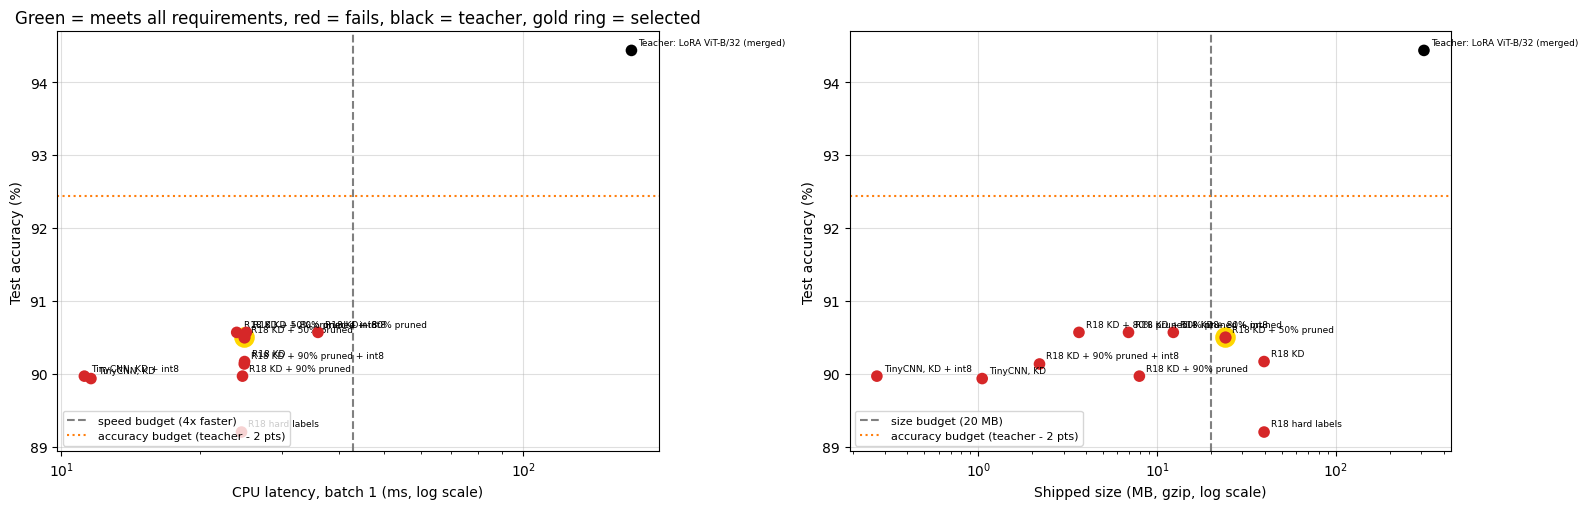

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, key, xl in zip(axes, ["cpu", "gz"], ["CPU latency, batch 1 (ms, log scale)", "Shipped size (MB, gzip, log scale)"]):
    for c in cands:
        color = "black" if c["is_teacher"] else ("tab:green" if c["passes"] else "tab:red")
        ax.scatter(c[key], c["test"], s=140 if c is chosen else 70, color=color, edgecolor="gold" if c is chosen else "none", linewidth=3, zorder=3)
        ax.annotate(c["name"].replace("ResNet-18, ", "R18 ").replace("distilled", "KD"), (c[key], c["test"]), textcoords="offset points", xytext=(5, 4), fontsize=6.5)
    ax.set_xscale("log"); ax.set_xlabel(xl); ax.set_ylabel("Test accuracy (%)"); ax.grid(True, alpha=0.4)
axes[0].axvline(T["cpu"] / MIN_SPEEDUP, color="gray", linestyle="--", label=f"speed budget ({MIN_SPEEDUP:g}x faster)")
axes[1].axvline(MAX_SIZE_MB, color="gray", linestyle="--", label=f"size budget ({MAX_SIZE_MB:g} MB)")
for ax in axes:
    ax.axhline(T["test"] - ACC_DROP_BUDGET, color="tab:orange", linestyle=":", label=f"accuracy budget (teacher - {ACC_DROP_BUDGET:g} pts)"); ax.legend(fontsize=8, loc="lower left")
axes[0].set_title("Green = meets all requirements, red = fails, black = teacher, gold ring = selected")
plt.tight_layout()
plt.show()

## 8. Stage D: Deployment

A model that only runs inside the notebook that trained it is not deployed. We take the selected model and make it run **outside PyTorch's training stack**, with checks that it still computes the same thing:

1. **TorchScript** (`torch.jit.trace`): a serialised, Python-free graph that loads with just `torch.jit.load`
2. **ONNX** + **ONNX Runtime**: the portable standard (servers, mobile, browsers). Wrapped in `try/except`, because export tooling changes between PyTorch versions
3. **Preprocessing check:** the most common deployment bug is **train/serve skew**, where the service resizes or normalizes an image slightly differently than training did. We verify that our standalone preprocessing function reproduces the training pipeline's tensors **exactly**
4. A small **`predict()`** function a web service could call

For every format we compare outputs against the eager PyTorch model on the same inputs.

In [ ]:
deploy_model = copy.deepcopy(chosen["model"]).to(CPU).eval()
shape = chosen["shape"]; assert chosen["prep"] is None, "capstone deployment path assumes a 128px student; if the teacher were selected, export at 224"
example = torch.randn(*shape)
with torch.no_grad():
    ref_out = deploy_model(example)
results = {"PyTorch eager": dict(ms=time_fn(deploy_model, example), diff=0.0)}

# ---- TorchScript ----
ts_path = "scene_model.ts"
traced = torch.jit.trace(deploy_model, example, check_trace=False)
traced.save(ts_path)
loaded = torch.jit.load(ts_path).eval()
with torch.no_grad():
    d = (loaded(example) - ref_out).abs().max().item()
results["TorchScript"] = dict(ms=time_fn(loaded, example, n_warmup=10), diff=d)
print(f"TorchScript: saved {os.path.getsize(ts_path)/2**20:.1f} MB | max |diff| vs eager = {d:.2e}")
assert d < 1e-3

# ---- ONNX + ONNX Runtime (optional) ----
onnx_path = "scene_model.onnx"
try:
    import subprocess, sys
    try:
        import onnx, onnxruntime as ort
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime"], check=True)
        import onnx, onnxruntime as ort
    kw = dict(input_names=["image"], output_names=["logits"], dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
    try:
        torch.onnx.export(deploy_model, example, onnx_path, dynamo=False, **kw)
    except TypeError:
        torch.onnx.export(deploy_model, example, onnx_path, **kw)
    sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    run = lambda x: sess.run(None, {"image": x.numpy()})[0]
    d = float(np.abs(run(example) - ref_out.numpy()).max())
    results["ONNX Runtime"] = dict(ms=time_fn(run, example, n_warmup=10), diff=d)
    print(f"ONNX: saved {os.path.getsize(onnx_path)/2**20:.1f} MB | max |diff| vs eager = {d:.2e} | dynamic batch works: {run(torch.randn(3, *shape[1:])).shape[0] == 3}")
    assert d < 1e-3
except Exception as e:
    print("ONNX export / ONNX Runtime step skipped:", type(e).__name__, str(e)[:150])

print(f"\n{'runtime':<16}{'CPU ms (batch 1)':>18}{'max |diff| vs eager':>22}")
for k, v in results.items():
    print(f"{k:<16}{v['ms']:>18.2f}{v['diff']:>22.2e}")

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


TorchScript: saved 42.8 MB | max |diff| vs eager = 0.00e+00


/tmp/ipykernel_370/2899249646.py:30: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(deploy_model, example, onnx_path, dynamo=False, **kw)
/tmp/ipykernel_370/1498189714.py:11: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  return (out, f) if return_feat else out


ONNX: saved 42.6 MB | max |diff| vs eager = 7.15e-07 | dynamic batch works: True

runtime           CPU ms (batch 1)   max |diff| vs eager
PyTorch eager                24.58              0.00e+00
TorchScript                  23.30              0.00e+00
ONNX Runtime                 14.38              7.15e-07


Preprocessing parity: standalone pipeline == training pipeline on 3 test images ✅


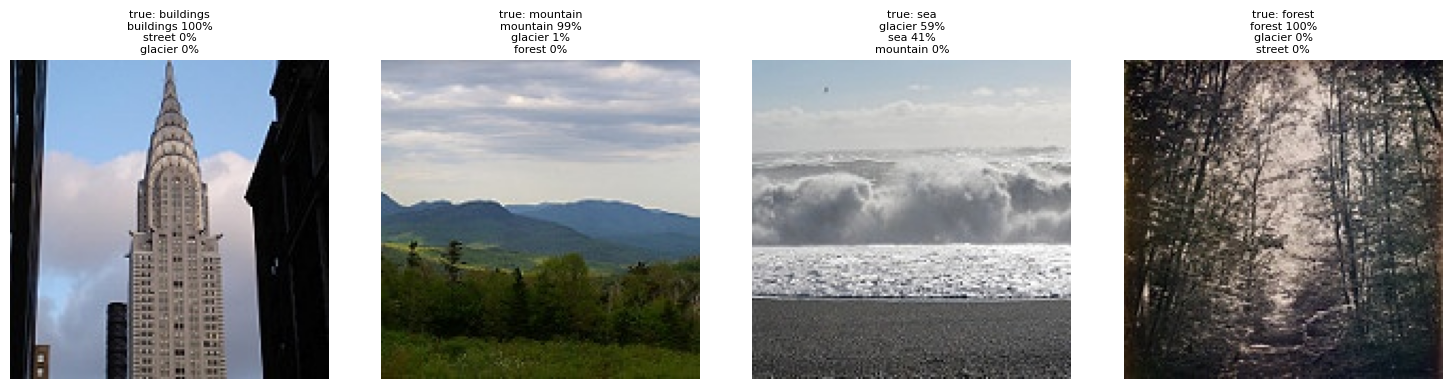

In [ ]:
# ---- preprocessing parity: the standalone preprocessing must reproduce the training pipeline EXACTLY ----
def preprocess_file(path):
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)     # same resize call as load_split
    x = torch.from_numpy(np.asarray(img).transpose(2, 0, 1).copy())
    return eval_t(tv_tensors.Image(x)).as_subclass(torch.Tensor).unsqueeze(0)

for i in (0, len(test_list) // 2, len(test_list) - 1):
    served = preprocess_file(test_list[i][0])[0]
    trained = eval_t(tv_tensors.Image(test_images[i])).as_subclass(torch.Tensor)
    assert torch.equal(served, trained), f"train/serve skew on image {i}"
print("Preprocessing parity: standalone pipeline == training pipeline on 3 test images ✅")

def predict(path, runner=loaded, topk=3):
    # path -> [(class, probability), ...]. Uses only the exported TorchScript model.
    with torch.no_grad():
        probs = runner(preprocess_file(path)).softmax(1)[0]
    p, idx = probs.topk(topk)
    return [(class_names[i], float(v)) for v, i in zip(p, idx)]

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, i in zip(axes, rng.choice(len(test_list), 4, replace=False)):
    top = predict(test_list[i][0])
    ax.imshow(Image.open(test_list[i][0]).convert("RGB")); ax.axis("off")
    ax.set_title(f"true: {test_list[i][1]}\n" + "\n".join(f"{c} {p*100:.0f}%" for c, p in top), fontsize=8)
plt.tight_layout()
plt.show()

## 9. Stage E: Final Evaluation and Honest Reporting

The test set is used **once**, for the selected model and the teacher. A single accuracy number hides uncertainty, so we report:

- **A paired bootstrap confidence interval** for (student accuracy − teacher accuracy). "Paired" means both models are scored on the *same* resampled images, which is the right test because their mistakes are correlated.
- **Confusion matrices**, to see *which* classes the compression hurt.
- **Concrete failures**: images the student gets wrong but the teacher gets right.

Test images: 3,000
Teacher accuracy :  94.43%
Selected student :  90.50%   (ResNet-18, distilled + 50% pruned)
Difference (student - teacher): -3.93 pts   95% bootstrap CI [-4.87, -3.00]
→ the interval excludes 0: a real accuracy gap.
Student is right where the teacher is wrong: 46 images | teacher right where student is wrong: 164 images


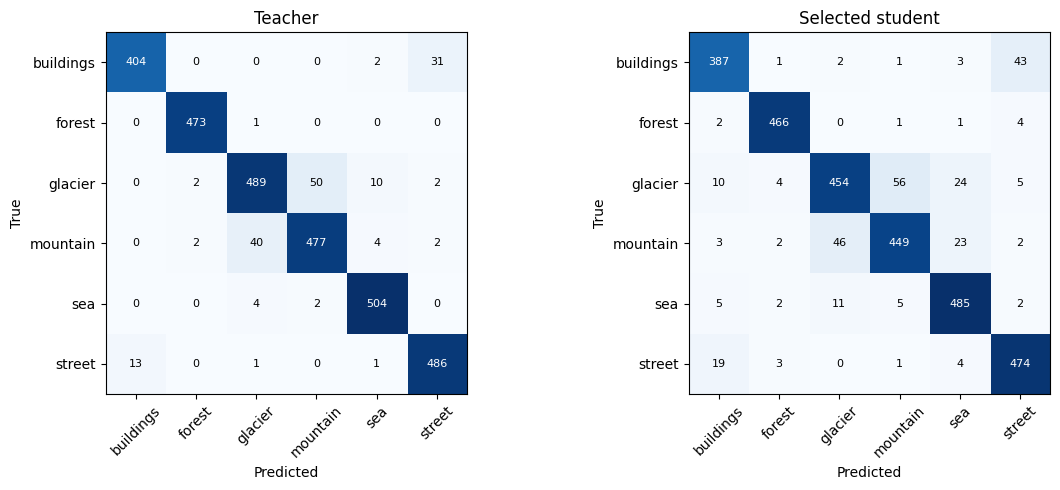

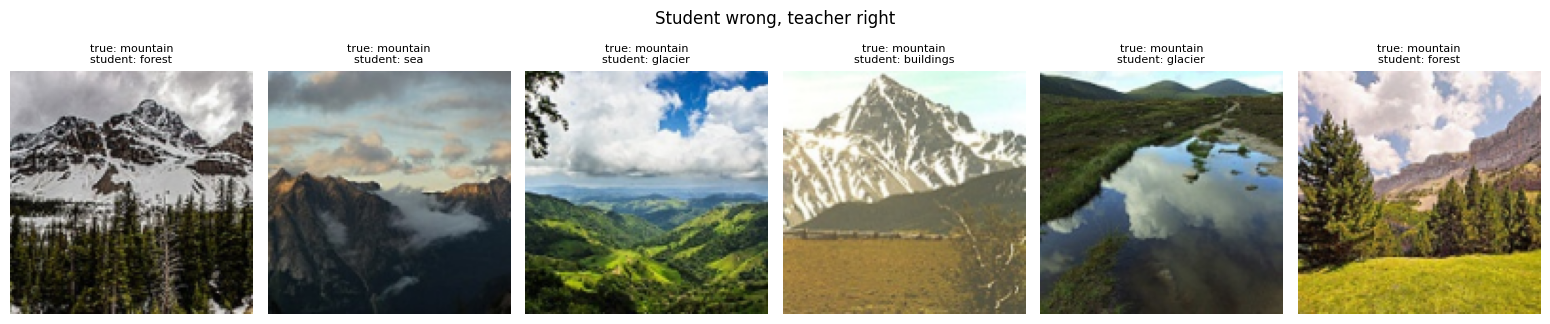

In [ ]:
student_test_logits = get_logits(chosen["model"], test_loader)
c_s = (student_test_logits.argmax(1) == test_labels).numpy().astype(float)
c_t = (teacher_test_logits.argmax(1) == test_labels).numpy().astype(float)
n = len(c_s)

rng = np.random.default_rng(SEED)
diffs = np.array([ (c_s[ix].mean() - c_t[ix].mean()) for ix in (rng.integers(0, n, n) for _ in range(2000)) ]) * 100
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Test images: {n:,}")
print(f"Teacher accuracy : {c_t.mean()*100:6.2f}%")
print(f"Selected student : {c_s.mean()*100:6.2f}%   ({chosen['name']})")
print(f"Difference (student - teacher): {(c_s.mean()-c_t.mean())*100:+.2f} pts   95% bootstrap CI [{lo:+.2f}, {hi:+.2f}]")
print("→", "the interval excludes 0: a real accuracy gap." if (lo > 0 or hi < 0) else "the interval includes 0: no reliable difference between student and teacher on this test set.")
print(f"Student is right where the teacher is wrong: {int(((c_s == 1) & (c_t == 0)).sum())} images | "
      f"teacher right where student is wrong: {int(((c_s == 0) & (c_t == 1)).sum())} images")

def confusion(logits):
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES)
    for t_, p_ in zip(test_labels, logits.argmax(1)):
        cm[t_, p_] += 1
    return cm
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, lg) in zip(axes, [("Teacher", teacher_test_logits), ("Selected student", student_test_logits)]):
    cm = confusion(lg); ax.imshow(cm, cmap="Blues")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=45); ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
plt.tight_layout()
plt.show()

bad = np.where((c_s == 0) & (c_t == 1))[0][:6]
if len(bad):
    fig, axes = plt.subplots(1, len(bad), figsize=(2.6 * len(bad), 3.2), squeeze=False)
    for ax, i in zip(axes[0], bad):
        ax.imshow(test_images[i].permute(1, 2, 0).numpy()); ax.axis("off")
        ax.set_title(f"true: {class_names[test_labels[i]]}\nstudent: {class_names[student_test_logits[i].argmax()]}", fontsize=8)
    plt.suptitle("Student wrong, teacher right", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No images where the student is wrong and the teacher is right.")

In [ ]:
# ---- an automatic one-paragraph model card draft from the measured numbers (edit and complete it yourself!) ----
sp = chosen["nonzero"] / chosen["params"]
print(f"""
MODEL CARD (draft)
------------------
Task          : 6-class natural-scene classification (Intel Image Classification), 128x128 RGB input.
Model         : {chosen['name']}  ({chosen['params']:.2f}M parameters, {chosen['nonzero']/chosen['params']*100:.0f}% non-zero).
Training      : LoRA-tuned ViT-B/32 teacher ({n_train:,} trainable parameters, {EPOCHS_TEACHER} epochs) -> distilled into the student
                (T=4, alpha=0.5, {EPOCHS_STUDENT} epochs) -> compressed as named above.
Test accuracy : {c_s.mean()*100:.2f}% (teacher {c_t.mean()*100:.2f}%; difference {(c_s.mean()-c_t.mean())*100:+.2f} pts, 95% CI [{lo:+.2f}, {hi:+.2f}]), {n:,} test images, single training seed.
Cost          : {chosen['gz']:.2f} MB shipped, {chosen['gflops']:.2f} GFLOPs, {chosen['cpu']:.1f} ms/image on this CPU ({T['cpu']/chosen['cpu']:.1f}x faster than the teacher).
Formats       : TorchScript ({os.path.getsize('scene_model.ts')/2**20:.1f} MB){', ONNX' if os.path.exists('scene_model.onnx') else ''}; outputs verified against eager PyTorch.
Requirements  : {'all three met on validation' if chosen['passes'] else 'NOT all met: see the selection table'}.
Known limits  : trained on one scene dataset (photographs, fixed 6 classes); no out-of-distribution or robustness testing; not evaluated for fairness
                or for performance on other cameras/regions; latency measured on one machine without a production runtime.
""")


MODEL CARD (draft)
------------------
Task          : 6-class natural-scene classification (Intel Image Classification), 128x128 RGB input.
Model         : ResNet-18, distilled + 50% pruned  (11.18M parameters, 50% non-zero).
Training      : LoRA-tuned ViT-B/32 teacher (299,526 trainable parameters, 4 epochs) -> distilled into the student
                (T=4, alpha=0.5, 12 epochs) -> compressed as named above.
Test accuracy : 90.50% (teacher 94.43%; difference -3.93 pts, 95% CI [-4.87, -3.00]), 3,000 test images, single training seed.
Cost          : 24.11 MB shipped, 1.18 GFLOPs, 24.9 ms/image on this CPU (6.9x faster than the teacher).
Formats       : TorchScript (42.8 MB), ONNX; outputs verified against eager PyTorch.
Requirements  : NOT all met: see the selection table.
Known limits  : trained on one scene dataset (photographs, fixed 6 classes); no out-of-distribution or robustness testing; not evaluated for fairness
                or for performance on other cameras/regions; la

## 🎓 Recap: The Whole Course in One Pipeline

| Week | Idea | Where it appeared here |
|---|---|---|
| 5 | Mixed precision, schedules, clipping | the shared `fit` loop |
| 8 | Transfer learning | the pretrained ViT as a starting point |
| 9-10 | Vision Transformers | the teacher, `[CLS]` embeddings |
| 11 | LoRA / PEFT | a 1 MB adapter, adapter portability, lossless merging |
| 12 | Forgetting, LwF | the distillation loss, reused for a different job |
| 13 | Distillation + compression | the student, pruning, int8 packing |
| **14** | **Engineering discipline** | requirements first, handoff checks, validation-based selection, uncertainty, deployment parity |

### The lessons that are not about any one technique
1. **Write requirements before results.** Selection by a rule fixed in advance is hard to fool yourself with.
2. **Check every handoff.** Adapter ↔ base, merged ↔ unmerged, packed ↔ unpacked, exported ↔ eager, served preprocessing ↔ training preprocessing. Each is a classic silent-failure point.
3. **Select on validation, report on test, once.**
4. **A number without uncertainty is an anecdote.** The bootstrap interval says how much of an observed gap you may believe.
5. **Size, FLOPs, latency and accuracy are four different axes.** Optimising one does not optimise the others (pruning shrinks the file, not the dense latency; weight-only int8 shrinks the download, not the compute).

### ⚠️ Honest limitations
- **One seed and short schedules.** Differences of a fraction of a point are noise; the bootstrap covers *test-set* sampling noise, **not** training-run variance. A rigorous study repeats training with several seeds.
- **Latency is for the machine you ran on**, in eager/TorchScript/ONNX Runtime fp32. Mobile NPUs, GPUs and int8 runtimes behave differently, so benchmark on the real target.
- The **teacher is modest** (ViT-B/32, small images) and the data is a **single, clean, small benchmark**; real products face distribution shift, class imbalance and adversarial or low-quality inputs that we did not test.
- Weight-only int8 is a **storage** optimisation here; activation quantization, QAT and structured pruning are the routes to real speedups.
- Educational use only. This is not a validated system.

### 🧪 Capstone Assignment (for students)
Submit a notebook **plus a one-page report** containing:
1. **Requirements** you chose (accuracy, speed, size) and why they suit a named deployment scenario
2. **The scorecard table** and the plot, with your selection and the rule you used
3. **Evidence of at least four handoff checks** (and what each would have caught)
4. **A paired-bootstrap comparison** between your final model and the teacher
5. **Failure analysis:** what the final model gets wrong that the teacher does not, and one concrete hypothesis for *why*
6. **Limitations** in your own words, with one experiment you would run next

**Stretch goals (pick one):** a *different dataset* from Kaggle · a *stronger student* (MobileNetV3 / EfficientNet-B0) · *structured pruning* that rebuilds a smaller network so latency really drops · *static int8 quantization* with a calibration set and an int8 runtime · *3 seeds* with mean ± std · a *continual-learning twist*: add a 7th class later with LwF (Week 12) and measure forgetting after compression · *distil without labels* using only teacher outputs on extra unlabeled photos.

#### Suggested grading rubric
| Area | Weight | Looks for |
|---|---|---|
| Correctness of the pipeline | 25% | all stages run; checks present and passing |
| Experimental discipline | 25% | requirements first, validation-based selection, test used once, controls (hard-label baseline, unpruned control) |
| Evaluation depth | 20% | uncertainty, confusion/failure analysis, honest comparison |
| Deployment | 15% | exported model verified, preprocessing parity, `predict()` works |
| Communication | 15% | clear report, honest limitations, claims that match the evidence |

<div align="center">

**© 2026 Md. Mehedi Hasan. All Rights Reserved.**

</div>